# Deep learning test set results

This notebook scores the Phase 2 networks on the 100 FD001 test engines and puts them next to the Phase 1 models. It is the only Phase 2 notebook that opens the test set, and it does so once. Every architecture, hyperparameter and the selected network were fixed by cross-validation in `06_sequence_models.ipynb` (read from `results/dl_best_params.json`) and `07_hybrid.ipynb`. Nothing below is tuned, and no result here changes an earlier choice.

## Protocol

Each network is retrained with the procedure used inside each cross-validation fold, with the same 80/20 split into fitting and early-stopping engines, now of all 100 training engines: 80 engines to fit on and 20 held out for early stopping, scalers are fitted on the 80 only, and the weights from the best early-stopping epoch are kept. No fixed epoch count is introduced, so no new hyperparameter is chosen here.

Neural networks vary with their random initialisation and batch order, so every network is trained with 5 seeds (42 to 46). The seed also chooses which 20 engines are held out for early stopping. Each metric is reported as the mean and standard deviation over the 5 seeds.

Each network predicts once per test engine, from the 30-cycle window ending at the engine's last observed cycle; engines with fewer than 30 cycles do not occur in FD001 test (shortest is 31). The hybrids also read the 142 engineered features at that cycle, computed over the engine's full observed history with statistics fitted on the training engines. As in Phase 1, predictions are scored against the true, uncapped RUL, and late stage means true RUL of at most 50.

The Phase 1 rows are not retrained: their per-engine predictions are read from `results/test_predictions.csv`, so they are exactly the numbers in the Phase 1 report.

The saved predictions in `results/dl_test_predictions.csv` were produced by running the 5 seeds in parallel, one process per seed with 2 CPU threads each. Retraining with `RETRAIN = True` in a single process uses a different thread count, which can change the last digits of individual predictions.

In [1]:
import json
import time
from itertools import pairwise
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.preprocessing import StandardScaler

from rul.data import USEFUL_SENSORS, add_rul, load_fd
from rul.evaluate import evaluate
from rul.features import FeatureScaler
from rul.holdout import last_row_positions, seed_bootstrap
from rul.hybrid import HybridNet, engineered_columns, hybrid_prepare
from rul.models import build_model
from rul.nets import build_net
from rul.sequences import last_windows, window_prepare
from rul.split import engine_split
from rul.train import fit_net, predict_net, set_seed

RETRAIN = False  # True retrains every network for every seed (about 30 minutes on CPU)
RUL_CAP = 125
LATE_CUT = 50
SEEDS = [42, 43, 44, 45, 46]
WINDOWS = (5, 10, 20)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110, "savefig.dpi": 220})


def save(fig, name):
    """Save a figure under figures/dl_results_<name>.png."""
    fig.savefig(ROOT / "figures" / f"dl_results_{name}.png", bbox_inches="tight", facecolor="white")


print(f"torch {torch.__version__}, {torch.get_num_threads()} CPU threads")

torch 2.14.1, 4 CPU threads


In [2]:
train, test, test_rul = load_fd("FD001")
train = add_rul(train, cap=RUL_CAP)

params = json.loads((ROOT / "results" / "dl_best_params.json").read_text())
assert params["target_cap"] == RUL_CAP and params["sensors"] == USEFUL_SENSORS
SENSORS, WINDOW, FIT, ES_FRAC = USEFUL_SENSORS, params["window"], params["fit"], params["es_frac"]
COLS = engineered_columns(SENSORS, WINDOWS)
# Hybrid head settings and residual hybrid settings, as cross-validated in 07_hybrid.ipynb.
HYBRID_HEAD = {"hidden": 64, "dropout": 0.2}
RESIDUAL_FIT = {"epochs": 60, "batch_size": 256, "lr": 1e-3, "patience": 10, "y_scale": 25.0}
RESIDUAL_XGB = {"subsample": 1.0, "reg_lambda": 5, "n_estimators": 400, "max_depth": 4,
                "learning_rate": 0.05, "colsample_bytree": 0.8, "n_jobs": 1}


def seq_net(name):
    """A sequence network with the configuration selected in 06_sequence_models.ipynb."""
    return build_net(name, len(SENSORS), **params["models"][name]["net"])


lr = {name: m["lr"] for name, m in params["models"].items()}
NETS = {
    "LSTM": ("window", lambda: seq_net("lstm"), lr["lstm"]),
    "Temporal CNN": ("window", lambda: seq_net("tcn"), lr["tcn"]),
    "Transformer": ("window", lambda: seq_net("transformer"), lr["transformer"]),
    "Hybrid, Transformer + features": (
        "hybrid", lambda: HybridNet(seq_net("transformer"), len(COLS), **HYBRID_HEAD), lr["transformer"]),
    "Hybrid, LSTM + features": (
        "hybrid", lambda: HybridNet(seq_net("lstm"), len(COLS), **HYBRID_HEAD), lr["lstm"]),
}
RESIDUAL = "Residual hybrid, XGBoost + Transformer"
print(f"Selected before the test set was opened: {params['selected']}")

Selected before the test set was opened: transformer


In [3]:
def run_seed(seed):
    """Train every network once with this seed and return its prediction per test engine."""
    inner, es = engine_split(train, val_frac=ES_FRAC, seed=seed)
    last = last_row_positions(test)

    # Sensor windows, scaled with statistics of the 80 fitting engines only.
    window_prep = window_prepare(SENSORS, WINDOW)
    X_inner, y_inner = window_prep(inner, inner)
    X_es, y_es = window_prep(inner, es)
    X_test, units = last_windows(test, SENSORS, WINDOW, scaler=StandardScaler().fit(inner[SENSORS]))
    assert units.equals(test_rul.index)

    # Windows plus engineered features. Test cycles have no RUL label, so the target column is NaN.
    hybrid_prep = hybrid_prepare(SENSORS, WINDOW, WINDOWS)
    H_inner, _ = hybrid_prep(inner, inner)
    H_es, _ = hybrid_prep(inner, es)
    (H_test_seq, H_test_feat), _ = hybrid_prep(inner, test.assign(rul=np.nan))
    H_test = (H_test_seq[last], H_test_feat[last])
    assert np.allclose(H_test[0], X_test)

    inputs = {"window": (X_inner, X_es, X_test), "hybrid": (H_inner, H_es, H_test)}
    preds, runs = {}, []
    for label, (kind, build, rate) in NETS.items():
        start = time.time()
        fit_in, es_in, test_in = inputs[kind]
        set_seed(seed)
        net = build()
        history = fit_net(net, fit_in, y_inner, es_in, y_es, lr=rate, seed=seed, **FIT)
        preds[label] = predict_net(net, test_in, y_scale=FIT["y_scale"])
        runs.append({"model": label, "seed": seed, "best_epoch": history["best_epoch"] + 1,
                     "seconds": time.time() - start})

    # Residual hybrid: XGBoost on the engineered features, a Transformer on its residuals.
    start = time.time()
    scaler = FeatureScaler.fit(inner, SENSORS, WINDOWS)
    feats = {name: scaler.transform(df.sort_values(["unit", "cycle"]).reset_index(drop=True))
             for name, df in {"inner": inner, "es": es, "test": test}.items()}
    xgb = build_model("xgboost", **RESIDUAL_XGB).fit(feats["inner"][COLS], feats["inner"]["rul"])
    residual = {name: (feats[name]["rul"] - xgb.predict(feats[name][COLS])).to_numpy(np.float32)
                for name in ("inner", "es")}
    set_seed(seed)
    net = seq_net("transformer")
    history = fit_net(net, X_inner, residual["inner"], X_es, residual["es"], seed=seed, **RESIDUAL_FIT)
    base = xgb.predict(feats["test"][COLS].iloc[last])
    preds[RESIDUAL] = np.clip(base + predict_net(net, X_test, y_scale=RESIDUAL_FIT["y_scale"]), 0, RUL_CAP)
    runs.append({"model": RESIDUAL, "seed": seed, "best_epoch": history["best_epoch"] + 1,
                 "seconds": time.time() - start})

    long = pd.DataFrame(preds, index=test_rul.index).melt(ignore_index=False, var_name="model",
                                                         value_name="rul_pred")
    return long.reset_index().assign(seed=seed), runs


pred_path, runs_path = ROOT / "results" / "dl_test_predictions.csv", ROOT / "results" / "dl_test_runs.csv"
if RETRAIN or not pred_path.exists():
    parts, runs = [], []
    for seed in SEEDS:
        seed_preds, seed_runs = run_seed(seed)
        parts.append(seed_preds)
        runs += seed_runs
        print(f"seed {seed} done ({sum(r['seconds'] for r in seed_runs):.0f} s)")
    dl_preds = pd.concat(parts, ignore_index=True)
    dl_preds.to_csv(pred_path, index=False)
    pd.DataFrame(runs).to_csv(runs_path, index=False)
else:
    dl_preds = pd.read_csv(pred_path)
    print(f"Loaded saved predictions from {pred_path.relative_to(ROOT)}; set RETRAIN = True to retrain")
runs = pd.read_csv(runs_path)
runs.groupby("model", sort=False)[["best_epoch", "seconds"]].agg(["mean", "min", "max"])

Loaded saved predictions from results/dl_test_predictions.csv; set RETRAIN = True to retrain


best_epoch          seconds           \
                                             mean min max     mean      min   
model                                                                         
LSTM                                         11.0   6  13   15.707   12.060   
Temporal CNN                                  7.2   6   8  108.824  101.341   
Transformer                                   8.4   3  12   64.572   45.385   
Hybrid, Transformer + features               18.0  10  26   94.539   68.050   
Hybrid, LSTM + features                      13.8  10  20   17.551   15.291   
Residual hybrid, XGBoost + Transformer        9.8   2  15   63.275   44.171   

                                                 
                                            max  
model                                            
LSTM                                     17.191  
Temporal CNN                            116.090  
Transformer                              78.290  
Hybrid, Transformer + features          123.647  
Hybrid, LSTM + features                  20.690  
Residual hybrid, XGBoost + Transformer   83.518

## Results

Every row below is scored on the same 100 engines. Phase 2 rows are the mean and standard deviation over 5 seeds; the Phase 1 rows are single deterministic fits and have no seed spread. `cv_rmse` repeats the cross-validation RMSE for reference only: cross-validation scores every cycle of the held-out training engines against the capped target, so it is not on the same scale as the test score.

In [4]:
phase1 = pd.read_csv(ROOT / "results" / "test_predictions.csv", index_col="unit")
PHASE1 = {"XGBoost (Phase 1)": "XGBoost/engineered", "Random Forest (Phase 1)": "Random Forest/engineered"}
assert phase1.index.equals(test_rul.index) and (phase1["true_rul"] == test_rul).all()
by_seed = {m: g.pivot(index="unit", columns="seed", values="rul_pred").loc[test_rul.index]
           for m, g in dl_preds.groupby("model", sort=False)}
MODELS = list(PHASE1) + list(by_seed)


def seed_matrix(model):
    """Predictions of shape (seeds, engines); Phase 1 models have a single row."""
    if model in PHASE1:
        return phase1[PHASE1[model]].to_numpy()[None, :]
    return by_seed[model].to_numpy().T


def score(truth, label):
    """Mean and std over seeds of every metric, one row per model."""
    rows = []
    for model in MODELS:
        per_seed = pd.DataFrame([evaluate(truth, p, late_cut=LATE_CUT) for p in seed_matrix(model)])
        rows.append({"model": model, "scored_against": label, "seeds": len(per_seed),
                     **per_seed.mean().to_dict(),
                     **per_seed.std(ddof=1).add_suffix("_std").to_dict()})
    return pd.DataFrame(rows)


dl_cv = pd.read_csv(ROOT / "results" / "dl_cv.csv").set_index("model")["rmse_mean"]
hybrid_cv = pd.read_csv(ROOT / "results" / "hybrid_cv.csv").set_index("model")["rmse_mean"]
models_cv = pd.read_csv(ROOT / "results" / "models_cv.csv")
models_cv = models_cv[(models_cv["scored against"] == "capped RUL") & (models_cv["features"] == "engineered")]
models_cv = models_cv.set_index("model")["rmse_mean"]
CV = {"XGBoost (Phase 1)": models_cv["xgboost"], "Random Forest (Phase 1)": models_cv["random_forest"],
      "LSTM": dl_cv["lstm"], "Temporal CNN": dl_cv["tcn"], "Transformer": dl_cv["transformer"],
      "Hybrid, Transformer + features": hybrid_cv["Hybrid (Transformer + Engineered)"],
      "Hybrid, LSTM + features": hybrid_cv["Hybrid (LSTM + Engineered)"],
      RESIDUAL: hybrid_cv["Hybrid (XGBoost + Transformer Residual)"]}

dl_metrics = pd.concat([score(test_rul, "true RUL"),
                        score(test_rul.clip(upper=RUL_CAP), f"true RUL capped at {RUL_CAP}")])
dl_metrics["cv_rmse"] = dl_metrics["model"].map(CV)
SHOW = ["rmse", "rmse_std", "mae", "mae_std", "nasa_score", "nasa_score_std", "rmse_early",
        "rmse_late", "rmse_late_std", "mae_late", "cv_rmse"]
dl_metrics[dl_metrics.scored_against == "true RUL"].set_index("model")[SHOW]

,rmse,rmse_std,mae,mae_std,nasa_score,nasa_score_std,rmse_early,rmse_late,rmse_late_std,mae_late,cv_rmse
model,,,,,,,,,,,
XGBoost (Phase 1),15.361,NaN,11.260,NaN,388.613,NaN,18.106,7.032,NaN,5.253,13.988
Random Forest (Phase 1),15.233,NaN,11.327,NaN,344.257,NaN,17.883,7.336,NaN,5.060,14.420
LSTM,16.024,0.665,11.798,0.541,622.265,144.865,19.068,6.214,1.150,4.892,14.017
Temporal CNN,16.841,0.926,12.506,0.665,583.730,191.345,19.728,8.104,2.124,5.477,15.910
Transformer,15.372,0.661,11.771,0.826,421.590,98.062,18.300,5.879,1.591,4.536,13.276
"Hybrid, Transformer + features",15.918,0.664,12.132,0.690,449.841,65.153,19.002,5.845,0.948,4.450,13.471
"Hybrid, LSTM + features",15.933,0.665,11.903,0.522,493.294,177.814,18.973,6.106,1.106,5.023,14.345
"Residual hybrid, XGBoost + Transformer",15.133,0.104,11.108,0.173,348.190,21.643,18.142,5.033,0.688,3.790,13.493


The selected network, the Transformer, reaches a test RMSE of 15.37 ± 0.66 cycles over the 5 seeds, the same as the selected Phase 1 model, XGBoost on engineered features (15.36). Cross-validation had put the Transformer 0.71 cycles ahead (13.28 against 13.99); on the test set that lead is gone. Its NASA score is higher (422 ± 98 against 389), so its errors are a little more often costly late ones.

The two-branch hybrid that adds the engineered features to the Transformer does not improve on the Transformer here (15.92 ± 0.66), although cross-validation had ranked it second. The residual hybrid, XGBoost corrected by a Transformer trained on XGBoost's residuals, has the lowest RMSE of all models (15.13) and the lowest NASA score of the networks (348), and is by far the most stable across seeds (RMSE spread 0.10, against 0.66 for the Transformer), because most of its prediction comes from the deterministic XGBoost. It was not the model selected by cross-validation, so it is reported, not chosen; its 0.23 cycle lead over XGBoost has a bootstrap interval of −1.14 to +0.77 cycles (computed after testing, so descriptive only). The LSTM (16.02) and the temporal CNN (16.84) are behind, the same order as in cross-validation.

The clearest difference between the phases is close to failure. Every network except the temporal CNN (8.10) has a lower late-stage RMSE than XGBoost (7.03): 5.88 for the Transformer, 5.85 for its hybrid, 6.21 for the LSTM and 5.03 for the residual hybrid. Early-stage RMSE is about the same for XGBoost (18.11), the residual hybrid (18.14) and the Transformer (18.30). The late stage has only 33 engines, and these late-stage gaps were not part of the pre-registered bootstrap, so they are a consistent pattern across seeds rather than a tested result.

## Is the difference larger than test-set noise?

The test set has only 100 engines, so a gap of a fraction of a cycle can come from which engines happen to be in it. As in Phase 1, a paired bootstrap resamples the 100 engines with replacement 10,000 times and scores both models on the same resample. For a network, each resample is scored with all 5 seeds and their RMSEs are averaged, so the interval belongs to the same mean-over-seeds number as the table. The comparisons were fixed before the test set was opened: the selected network (Transformer) against the selected Phase 1 model (XGBoost), and the Transformer hybrid against both of its parents.

In [5]:
PAIRS = [("Transformer", "XGBoost (Phase 1)"),
         ("Hybrid, Transformer + features", "XGBoost (Phase 1)"),
         ("Hybrid, Transformer + features", "Transformer"),
         (RESIDUAL, "XGBoost (Phase 1)")]  # descriptive: not fixed before testing
truth = test_rul.to_numpy(dtype=float)
bootstrap = pd.DataFrame([
    {"comparison": f"{a} minus {b}",
     **seed_bootstrap(seed_matrix(a), seed_matrix(b), truth)}
    for a, b in PAIRS]).set_index("comparison")
bootstrap

,rmse_difference,low,high
comparison,,,
Transformer minus XGBoost (Phase 1),0.011,-2.282,2.207
"Hybrid, Transformer + features minus XGBoost (Phase 1)",0.557,-1.475,2.572
"Hybrid, Transformer + features minus Transformer",0.546,-0.216,1.324
"Residual hybrid, XGBoost + Transformer minus XGBoost (Phase 1)",-0.228,-1.142,0.766


None of the three intervals excludes zero. The Transformer and XGBoost are tied: the point difference is 0.01 cycles and the interval runs from about −2.3 to +2.2. The Transformer hybrid is 0.55 cycles worse than the Transformer alone, with an interval of about −0.2 to +1.3, so the test set does not show that adding the engineered features to the Transformer helps or hurts. With 100 test engines, overall RMSE differences of a cycle or two between these models cannot be resolved.

## Predicted and true RUL per engine

Engines are sorted by true RUL. Each network's marker is its prediction averaged over the 5 seeds, for readability; the bars around the Transformer's markers span its lowest and highest seed.

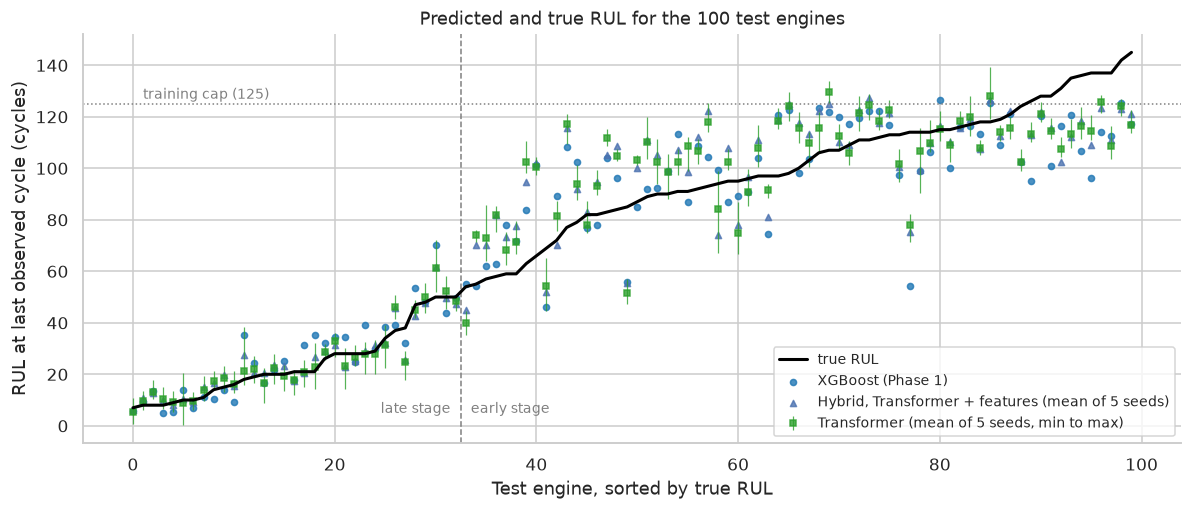

In [6]:
order = test_rul.sort_values().index
x = np.arange(len(order))
n_late = int((test_rul <= LATE_CUT).sum())
mean_pred = {m: by_seed[m].mean(axis=1) for m in by_seed}
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(x, test_rul.loc[order], color="black", lw=2, label="true RUL", zorder=3)
ax.scatter(x, phase1.loc[order, PHASE1["XGBoost (Phase 1)"]], s=16, marker="o", alpha=0.8,
           label="XGBoost (Phase 1)", color="tab:blue")
tr = by_seed["Transformer"].loc[order]
ax.errorbar(x, tr.mean(axis=1), yerr=[tr.mean(axis=1) - tr.min(axis=1), tr.max(axis=1) - tr.mean(axis=1)],
            fmt="s", ms=4, alpha=0.8, lw=0.8, color="tab:green", label="Transformer (mean of 5 seeds, min to max)")
ax.scatter(x, mean_pred["Hybrid, Transformer + features"].loc[order], s=16, marker="^", alpha=0.8,
           label="Hybrid, Transformer + features (mean of 5 seeds)")
ax.axhline(RUL_CAP, color="grey", ls=":", lw=1)
ax.text(1, RUL_CAP + 2, f"training cap ({RUL_CAP})", color="grey", fontsize=9)
ax.axvline(n_late - 0.5, color="grey", ls="--", lw=1)
ax.text(n_late + 0.5, 5, "early stage", color="grey", fontsize=9)
ax.text(n_late - 1.5, 5, "late stage", color="grey", fontsize=9, ha="right")
ax.set(xlabel="Test engine, sorted by true RUL", ylabel="RUL at last observed cycle (cycles)",
       title="Predicted and true RUL for the 100 test engines")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
save(fig, "pred_vs_true")

## Error by true RUL, ML against DL

The error is predicted minus true RUL, so a positive error means failure predicted later than it will happen, the costly direction. Networks use their 5-seed mean prediction here.

,engines,XGBoost (Phase 1),Transformer,"Hybrid, Transformer + features","Residual hybrid, XGBoost + Transformer"
true RUL bucket,,,,,
0 to 25,19,6.582,2.530,3.617,4.068
26 to 50,14,7.600,5.691,5.744,4.520
51 to 75,10,17.485,21.568,20.500,17.377
76 to 100,24,15.684,19.008,19.502,15.225
101 to 125,22,16.708,12.425,13.129,16.069
126 to 145,11,24.974,19.954,20.420,24.115


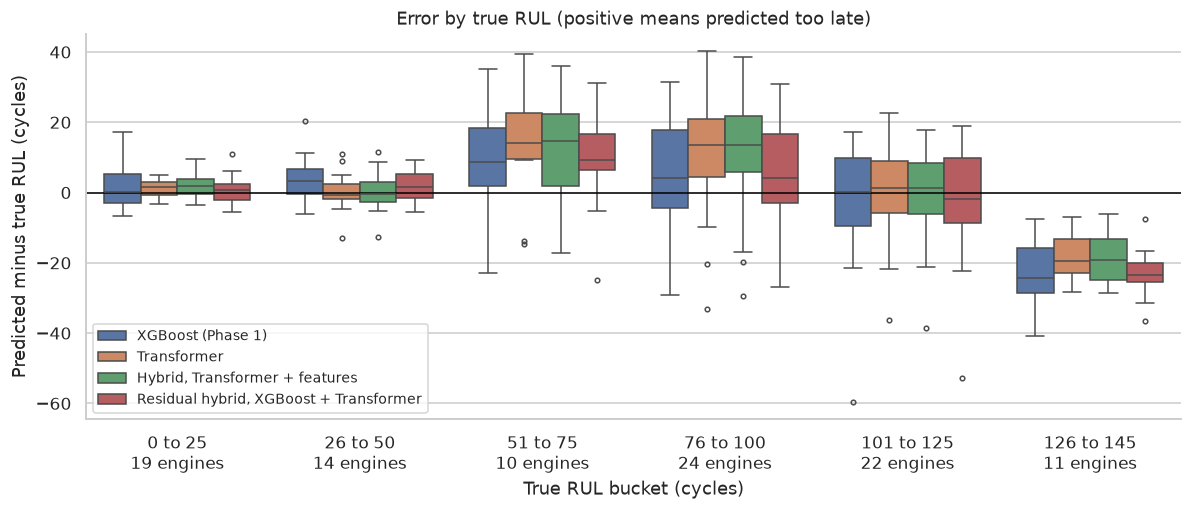

In [7]:
edges = [0, 25, 50, 75, 100, 125, test_rul.max()]
bucket_names = [f"{lo + 1 if lo else 0} to {hi}" for lo, hi in pairwise(edges)]
buckets = pd.cut(test_rul, bins=edges, labels=bucket_names, include_lowest=True)
SHOWN = ["XGBoost (Phase 1)", "Transformer", "Hybrid, Transformer + features", RESIDUAL]
errors = pd.DataFrame({m: (phase1[PHASE1[m]] if m in PHASE1 else mean_pred[m]) - test_rul for m in SHOWN})
long = errors.assign(bucket=buckets.astype(str)).melt(id_vars="bucket", var_name="model", value_name="error")
bucket_order = [str(b) for b in buckets.cat.categories]
counts = buckets.value_counts().reindex(buckets.cat.categories)

fig, ax = plt.subplots(figsize=(11, 4.8))
sns.boxplot(data=long, x="bucket", y="error", hue="model", order=bucket_order, ax=ax, fliersize=3, linewidth=1)
ax.axhline(0, color="black", lw=1)
ax.set_xticks(range(len(bucket_order)), [f"{b}\n{n} engines" for b, n in zip(bucket_order, counts)])
ax.set(xlabel="True RUL bucket (cycles)", ylabel="Predicted minus true RUL (cycles)",
       title="Error by true RUL (positive means predicted too late)")
ax.legend(fontsize=9)
fig.tight_layout()
save(fig, "error_by_bucket")

bucket_table = errors.groupby(buckets, observed=True).agg(lambda e: np.sqrt(np.mean(e**2)))
bucket_table.insert(0, "engines", counts.to_numpy())
bucket_table.rename_axis("true RUL bucket")

The networks gain where maintenance is decided. For true RUL up to 25 cycles (19 engines), the Transformer's 5-seed mean prediction has an RMSE of 2.5 cycles against 6.6 for XGBoost, and from 26 to 50 cycles 5.7 against 7.6. They lose in the middle: from 51 to 100 cycles, where degradation first becomes visible, the Transformer's RMSE is 19 to 22 cycles against 15.7 to 17.5 for XGBoost. Above 100 cycles the Transformer is better again (12.4 against 16.7 from 101 to 125, and 20.0 against 25.0 above the cap). The residual hybrid follows XGBoost in the middle buckets and keeps most of the Transformer's gain near failure, which is why it has the lowest overall RMSE.

In [8]:
pd.DataFrame({
    "mean error": errors.mean(),
    "predicted too late": (errors > 0).mean(),
    "late by more than 20": (errors > 20).sum(),
    "early by more than 20": (errors < -20).sum(),
    "largest late error": errors.max(),
}).T

,XGBoost (Phase 1),Transformer,"Hybrid, Transformer + features","Residual hybrid, XGBoost + Transformer"
mean error,0.029,1.887,1.972,-0.503
predicted too late,0.530,0.560,0.590,0.500
late by more than 20,9.000,11.000,11.000,7.000
early by more than 20,12.000,9.000,8.000,13.000
largest late error,35.225,40.188,38.597,31.216


The Transformer and its hybrid lean late: their mean error is about +1.9 cycles, 56% and 59% of their predictions are late, and 11 of each are more than 20 cycles late, against 9 for XGBoost. That is why their NASA scores are higher than XGBoost's despite the same RMSE. The residual hybrid has the fewest predictions more than 20 cycles late (7) and the smallest largest late error (31 cycles).

## Comparison with published FD001 deep learning results

Published FD001 results usually score against test labels clipped at 125, so our models are rescored the same way here (the capped block of `results/dl_test_metrics.csv`). The published rows are `results/dl_published.csv` from the deep learning literature review, with the caveats listed there: values are often transcribed from another paper's comparison table, and protocols differ in window length, cap, label clipping and how results were selected.

In [9]:
published = pd.read_csv(ROOT / "results" / "dl_published.csv")[["method", "source", "rmse", "nasa_score"]]
capped = dl_metrics[dl_metrics.scored_against == f"true RUL capped at {RUL_CAP}"].set_index("model")
ours = pd.DataFrame({"method": [f"{m} (ours)" for m in capped.index], "source": "this project",
                     "rmse": capped["rmse"].to_numpy(), "nasa_score": capped["nasa_score"].to_numpy()})
dl_comparison = (pd.concat([published.assign(where="published"), ours.assign(where="this project")])
                 .sort_values("rmse").reset_index(drop=True))
dl_comparison.index += 1
dl_comparison

,method,source,rmse,nasa_score,where
1,GCU-Transformer,Mo et al. 2021,11.270,NaN,published
2,DAST,Zhang et al. 2022,11.430,203.150,published
3,1D CNN,Li et al. 2018,12.610,274.000,published
4,ATS2S,Ragab et al. 2020,12.630,243.000,published
5,HDNN,Al-Dulaimi et al. 2019,13.020,245.000,published
6,BLCNN,Liu et al. 2019,13.180,302.000,published
7,"Residual hybrid, XGBoost + Transformer (ours)",this project,13.876,309.265,this project
8,Random Forest (Phase 1) (ours),this project,14.023,309.535,this project
9,XGBoost (Phase 1) (ours),this project,14.080,346.956,this project
10,Transformer (ours),this project,14.306,391.933,this project


Against labels clipped at 125, the residual hybrid (13.88), our Phase 1 Random Forest (14.02) and XGBoost (14.08) and the Transformer (14.31) rank 7th to 10th of 21 by RMSE. They are ahead of CNN-LSTM (14.40), the LSTM with attention and handcrafted features (14.53) and the five other published models below them, and behind six published deep models from BLCNN (13.18) to GCU-Transformer (11.27). Our own LSTM, temporal CNN and two-branch hybrids score between 14.78 and 15.64. The caveats from the literature review apply: several published values are transcribed from other papers, and protocols differ in details that move RMSE by about a cycle.

## Summary

- The selected Transformer reaches a test RMSE of 15.37 ± 0.66 over 5 seeds, tied with the selected Phase 1 XGBoost (15.36); the paired bootstrap interval for the difference is about −2.3 to +2.2 cycles. Learning from raw 30-cycle windows matches, but does not beat, hand-engineered degradation features on this test set.
- The Transformer's 0.71 cycle lead in cross-validation did not carry to the test set, and neither did the two-branch hybrid's place second in cross-validation (test RMSE 15.92).
- Every network except the temporal CNN is more accurate than XGBoost close to failure (late-stage RMSE 5.0 to 6.2 against 7.03; up to 25 cycles, 2.5 against 6.6 for the Transformer) and less accurate from 51 to 100 cycles. The networks also predict late slightly more often, which raises their NASA scores.
- The residual hybrid, XGBoost corrected by a Transformer, has the lowest test RMSE (15.13) and is the most stable across seeds (spread 0.10). It was not selected by cross-validation, so it is reported rather than chosen.
- Against labels clipped at 125, our best four models rank 7th to 10th of 21 next to published FD001 results, behind six published deep models.

The metrics are saved as `results/dl_test_metrics.csv`, the bootstrap as `results/dl_test_bootstrap.csv`, the published comparison as `results/dl_test_published_comparison.csv`, the per-seed predictions as `results/dl_test_predictions.csv`, and the figures as `figures/dl_results_*.png`.

In [10]:
dl_metrics.to_csv(ROOT / "results" / "dl_test_metrics.csv", index=False)
bootstrap.to_csv(ROOT / "results" / "dl_test_bootstrap.csv")
dl_comparison.to_csv(ROOT / "results" / "dl_test_published_comparison.csv", index_label="rank")
print("Saved results/dl_test_metrics.csv, dl_test_bootstrap.csv, dl_test_published_comparison.csv")

Saved results/dl_test_metrics.csv, dl_test_bootstrap.csv, dl_test_published_comparison.csv
